This notebook covers the exploratory data analysis of the dataset from https://www.kaggle.com/datasets/patrickfleith/nasa-battery-dataset which was adapted/streamlined from B. Saha and K. Goebel (2007). “Battery Data Set”, NASA Prognostics Data Repository, NASA Ames Research Center, Moffett Field, CA. 

# 1. Importing Libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

np.set_printoptions(legacy="1.25")

In [2]:
charge_df = pd.read_pickle("charge_df.pkl")
discharge_df = pd.read_pickle("discharge_df.pkl")
eis_df = pd.read_pickle("eis_df.pkl")

# 2. Decompose Complex EIS Values
The raw impedance/current values from the CSV files are complex numbers — split each into real (`Re_...`) and imaginary (`Im_...`) components so they can be used as normal numeric features, then drop the original complex columns.

In [3]:
# Split complex EIS quantities (current, impedance) into real/imaginary components; add Re/Rct as plain columns
eis_df['Re_Sense_Current'] = eis_df['Sense_current'].apply(lambda x: x.real)
eis_df['Im_Sense_Current'] = eis_df['Sense_current'].apply(lambda x: x.imag)
eis_df['Re_Battery_Current'] = eis_df['Battery_current'].apply(lambda x: x.real)
eis_df['Im_Battery_Current'] = eis_df['Battery_current'].apply(lambda x: x.imag)
eis_df['Re_Current_Ratio'] = eis_df['Current_ratio'].apply(lambda x: x.real)
eis_df['Im_Current_Ratio'] = eis_df['Current_ratio'].apply(lambda x: x.imag)
eis_df['Re_Battery_Impedance'] = eis_df['Battery_impedance'].apply(lambda x: x.real)
eis_df['Im_Battery_Impedance'] = eis_df['Battery_impedance'].apply(lambda x: x.imag)
eis_df['R_Electrolyte'] = eis_df['Re']
eis_df['R_Charge_Transfer'] = eis_df['Rct']
# Rectified_Impedance has less values, presumably NaN
mask = eis_df['Rectified_Impedance'].notna()
eis_df['Re_Rectified_Impedance'] = np.nan
eis_df['Im_Rectified_Impedance'] = np.nan
eis_df.loc[mask, 'Re_Rectified_Impedance'] = eis_df.loc[mask, 'Rectified_Impedance'].apply(lambda x: x.real)
eis_df.loc[mask, 'Im_Rectified_Impedance'] = eis_df.loc[mask, 'Rectified_Impedance'].apply(lambda x: x.imag)

eis_df.drop(columns=['Re', 'Rct'], inplace=True)

In [4]:
#adding modulus Z (|Z|) to the dataframe
eis_df['Mod_Battery_Impedance'] = (eis_df['Re_Battery_Impedance']**2 + eis_df['Im_Battery_Impedance']**2)**0.5

In [5]:
eis_df['Im_Rectified_Impedance'].isna().sum()

17172

In [6]:
#Sanity check
print("Charge Dataframe:")
print(charge_df.info())
print("\nDischarge Dataframe:")
print(discharge_df.info())
print("\nEIS Dataframe:")
print(eis_df.info())

Charge Dataframe:
<class 'pandas.DataFrame'>
Index: 6206968 entries, 0 to 6512875
Data columns (total 10 columns):
 #   Column                Dtype         
---  ------                -----         
 0   Voltage_measured      float64       
 1   Current_measured      float64       
 2   Temperature_measured  float64       
 3   Current_charge        float64       
 4   Voltage_charge        float64       
 5   Time                  float64       
 6   Cell_ID               str           
 7   Cycle_Number          int64         
 8   Ambient_Temperature   int64         
 9   Time_abs              datetime64[us]
dtypes: datetime64[us](1), float64(6), int64(2), str(1)
memory usage: 520.9 MB
None

Discharge Dataframe:
<class 'pandas.DataFrame'>
RangeIndex: 746334 entries, 0 to 746333
Data columns (total 16 columns):
 #   Column                Non-Null Count   Dtype         
---  ------                --------------   -----         
 0   Voltage_measured      746334 non-null  float64      

# 3. Label Discharge Type & Compute SoH
Tag each row with its discharge current profile (constant 1A/2A/4A, alternating, square-wave) based on known Cell_ID groupings, clean the `Capacity` column, and compute **State of Health** = capacity / max capacity per cell.

In [7]:
#Discharge Current Types
discharge_type = []
alter_241 = ['B0042', 'B0043', 'B0044']
alter_41 = ['B0041']
alter_4124 = ['B0038', 'B0039', 'B0040']
constant_1A = ['B0045', 'B0046', 'B0047', 'B0048']
constant_2A = ['B0005', 'B0006', 'B0007', 'B0018', 'B0036', 'B0053', 'B0054', 'B0055', 'B0056']
constant_4A = ['B0029', 'B0030', 'B0031', 'B0032', 'B0033', 'B0034']
square_4A = ['B0025', 'B0026', 'B0027', 'B0028']
for cell in discharge_df['Cell_ID']:
  if cell in alter_241:
    discharge_type.append('Alter_2-4-1')
  elif cell in alter_41:
    discharge_type.append('Alter_4-1')
  elif cell in alter_4124:
    discharge_type.append('Alter_4-1-2-4')
  elif cell in constant_1A:
    discharge_type.append('Constant_1A')
  elif cell in constant_2A:
    discharge_type.append('Constant_2A')
  elif cell in constant_4A:
    discharge_type.append('Constant_4A')
  elif cell in square_4A:
    discharge_type.append('Square_4A')

discharge_df['Discharge_Type'] = discharge_type

In [8]:
#State of Health = current capacity/max capacity
discharge_df['Capacity'] = pd.to_numeric(discharge_df['Capacity'], errors='coerce')
discharge_df = discharge_df.dropna(subset=['Capacity'])

discharge_df['SoH'] = (
    discharge_df
    .groupby('Cell_ID')['Capacity']
    .transform(lambda x: x / x.max())
)

In [9]:
# Confirm dtypes and row counts after tagging discharge type and computing SoH
discharge_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 746334 entries, 0 to 746333
Data columns (total 18 columns):
 #   Column                Non-Null Count   Dtype         
---  ------                --------------   -----         
 0   Voltage_measured      746334 non-null  float64       
 1   Current_measured      746334 non-null  float64       
 2   Temperature_measured  746334 non-null  float64       
 3   Current_load          746334 non-null  float64       
 4   Voltage_load          746334 non-null  float64       
 5   Time                  746334 non-null  float64       
 6   Cell_ID               746334 non-null  str           
 7   Cycle_Number          746334 non-null  int64         
 8   Ambient_Temperature   746334 non-null  int64         
 9   Time_abs              746334 non-null  datetime64[us]
 10  Capacity              746334 non-null  float64       
 11  discharge_mode        746334 non-null  str           
 12  discharge_current_A   594827 non-null  float64       
 13  ambient_C 

# 4. EDA: SoH Trends by Discharge Type
Plot SoH vs cycle number for every discharge type to spot cells with abnormal degradation (early failures, premature end-of-life).

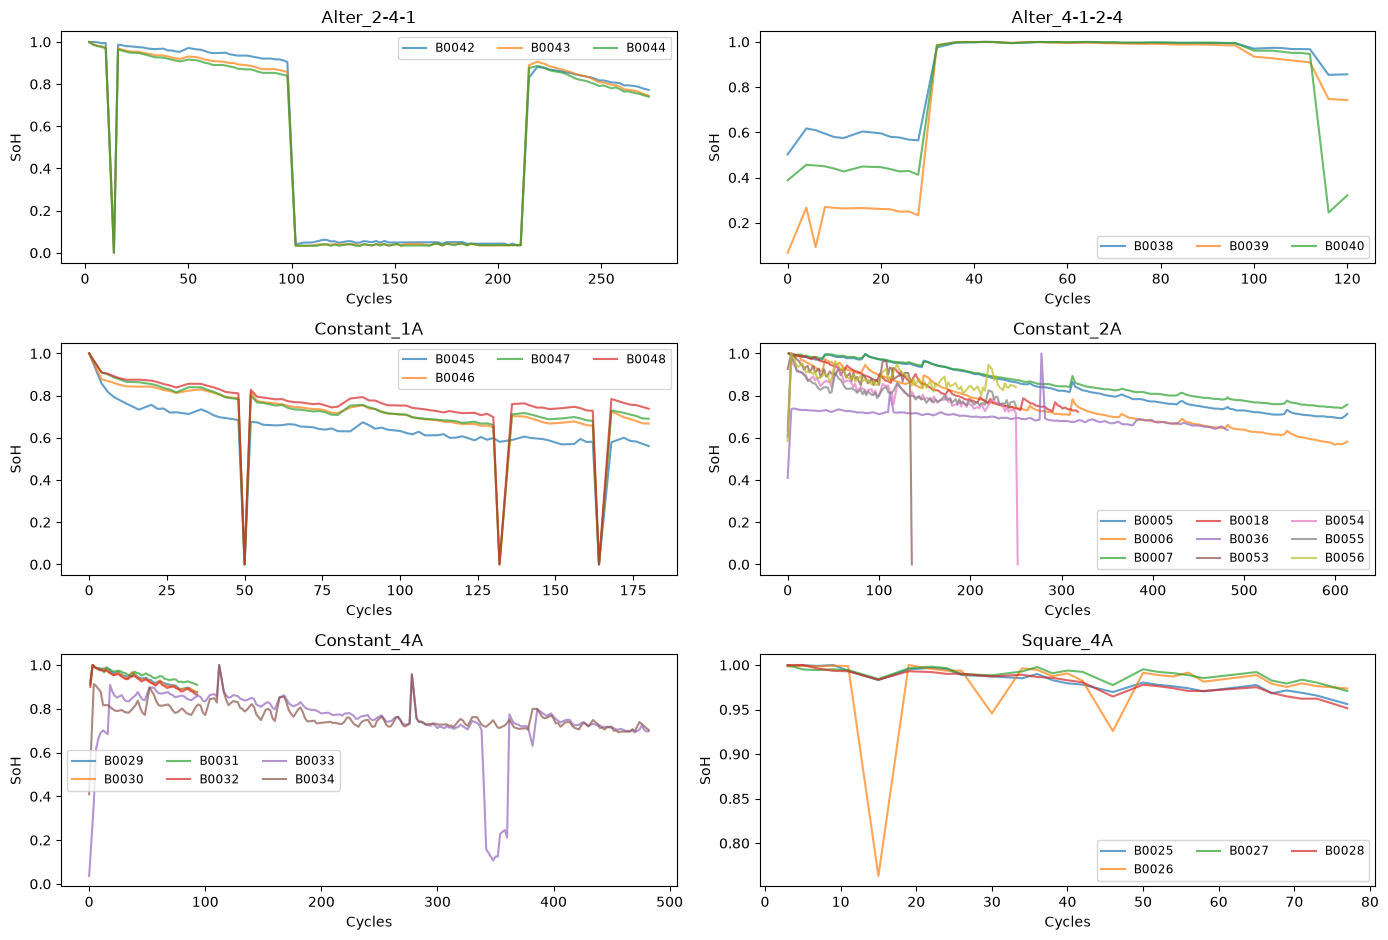

In [10]:
# Plot SoH vs. cycle number for each discharge type to spot abnormal degradation
alt_241 = discharge_df[discharge_df['Discharge_Type'] == 'Alter_2-4-1']
alt_4124 = discharge_df[discharge_df['Discharge_Type'] == 'Alter_4-1-2-4']
const_1A = discharge_df[discharge_df['Discharge_Type'] == 'Constant_1A']
const_2A = discharge_df[discharge_df['Discharge_Type'] == 'Constant_2A']
const_4A = discharge_df[discharge_df['Discharge_Type'] == 'Constant_4A']
square_4A = discharge_df[discharge_df['Discharge_Type'] == 'Square_4A']

discharge_types = {
    "Alter_2-4-1": alt_241,
    "Alter_4-1-2-4": alt_4124,
    "Constant_1A": const_1A,
    "Constant_2A": const_2A,
    "Constant_4A": const_4A,
    "Square_4A": square_4A,
}


fig, axes = plt.subplots(3, 2, figsize=(14, 10), sharex=False, sharey=False)
axes = axes.flatten()

for ax, (label, df) in zip(axes, discharge_types.items()):
    for cell_id, group in df.groupby("Cell_ID"):
        ax.plot(group["Cycle_Number"], group["SoH"], label=cell_id, alpha=0.7)
    ax.set_title(label)
    ax.set_xlabel("Cycles")
    ax.set_ylabel("SoH")
    ax.legend(fontsize="small", loc="best", ncol=3)

plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()


Here, we see that some cells encountered some fatal errors that caused the measurement to end or experiencing end-of-life state (SoH < 70%) prematurely. While interesting, the goal of this project is to predict the state of health of normal cells, so we will remove those cells.

# 5. Remove Problem Cells
Based on the plots above, drop cells that failed prematurely or show clearly anomalous degradation, since the goal is modeling *normal* degradation behavior.

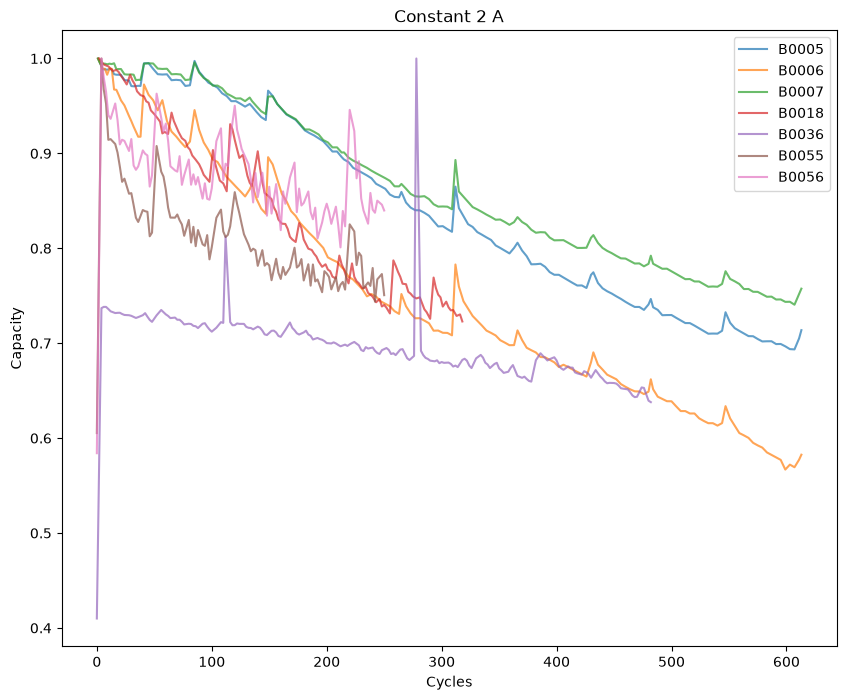

In [11]:
# Re-plot Constant_2A cells after dropping the ones with premature/anomalous end-of-life
const_2A = discharge_df[discharge_df['Discharge_Type'] == 'Constant_2A']
drop2A = ['B0036', 'B0005', 'B0006', 'B0007', 'B0018', 'B0055', 'B0056']
const_2A = const_2A[const_2A['Cell_ID'].isin(drop2A)]
const_2A.groupby('Cell_ID').count()
plt.figure(figsize=(10, 8))
for cell_id, group in const_2A.groupby("Cell_ID"):
        plt.plot(group["Cycle_Number"], group["SoH"], label=cell_id, alpha=0.7)
plt.xlabel('Cycles')
plt.ylabel('Capacity')
plt.title('Constant 2 A')
plt.legend()
plt.show()

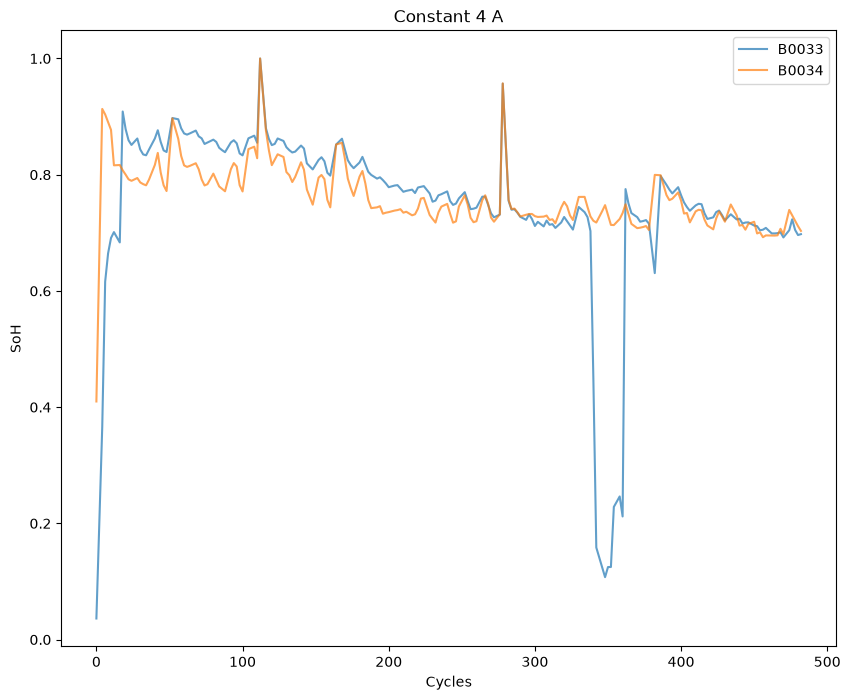

In [12]:
# Re-plot Constant_4A cells after dropping the elevated-temperature (43C) batch
const_4A = discharge_df[discharge_df['Discharge_Type'] == 'Constant_4A']
drop4A = ['B0029', 'B0030', 'B0031', 'B0032']
const_4A = const_4A[~const_4A['Cell_ID'].isin(drop4A)]
const_4A.groupby('Cell_ID').count()
plt.figure(figsize=(10, 8))
for cell_id, group in const_4A.groupby("Cell_ID"):
        plt.plot(group["Cycle_Number"], group["SoH"], label=cell_id, alpha=0.7)
plt.xlabel('Cycles')
plt.ylabel('SoH')
plt.title('Constant 4 A')
plt.legend()
plt.show()

To Drop: Batteries 29-32, 49-54

In [13]:
# Drop cells that fail prematurely or show anomalous degradation from all three dataframes
drop = ['B0029', 'B0030', 'B0031', 'B0032', 'B0049', 'B0050', 'B0051', 'B0052', 'B0053', 'B0054']

charge_df = charge_df[~charge_df['Cell_ID'].isin(drop)]
discharge_df = discharge_df[~discharge_df['Cell_ID'].isin(drop)]
eis_df = eis_df[~eis_df['Cell_ID'].isin(drop)]

In [14]:
# Confirm dtypes and row counts after removing the problem cells
print("Charge Dataframe:")
print(charge_df.info())
print("\nDischarge Dataframe:")
print(discharge_df.info())
print("\nEIS Dataframe:")
print(eis_df.info())

Charge Dataframe:
<class 'pandas.DataFrame'>
Index: 5444268 entries, 0 to 6512875
Data columns (total 10 columns):
 #   Column                Dtype         
---  ------                -----         
 0   Voltage_measured      float64       
 1   Current_measured      float64       
 2   Temperature_measured  float64       
 3   Current_charge        float64       
 4   Voltage_charge        float64       
 5   Time                  float64       
 6   Cell_ID               str           
 7   Cycle_Number          int64         
 8   Ambient_Temperature   int64         
 9   Time_abs              datetime64[us]
dtypes: datetime64[us](1), float64(6), int64(2), str(1)
memory usage: 456.9 MB
None

Discharge Dataframe:
<class 'pandas.DataFrame'>
Index: 687175 entries, 0 to 746333
Data columns (total 18 columns):
 #   Column                Non-Null Count   Dtype         
---  ------                --------------   -----         
 0   Voltage_measured      687175 non-null  float64       
 1 

# 6. Re-check Cleaned Data
Re-plot SoH trends and correlations after dropping the problem cells to confirm the cleaned dataset looks reasonable.

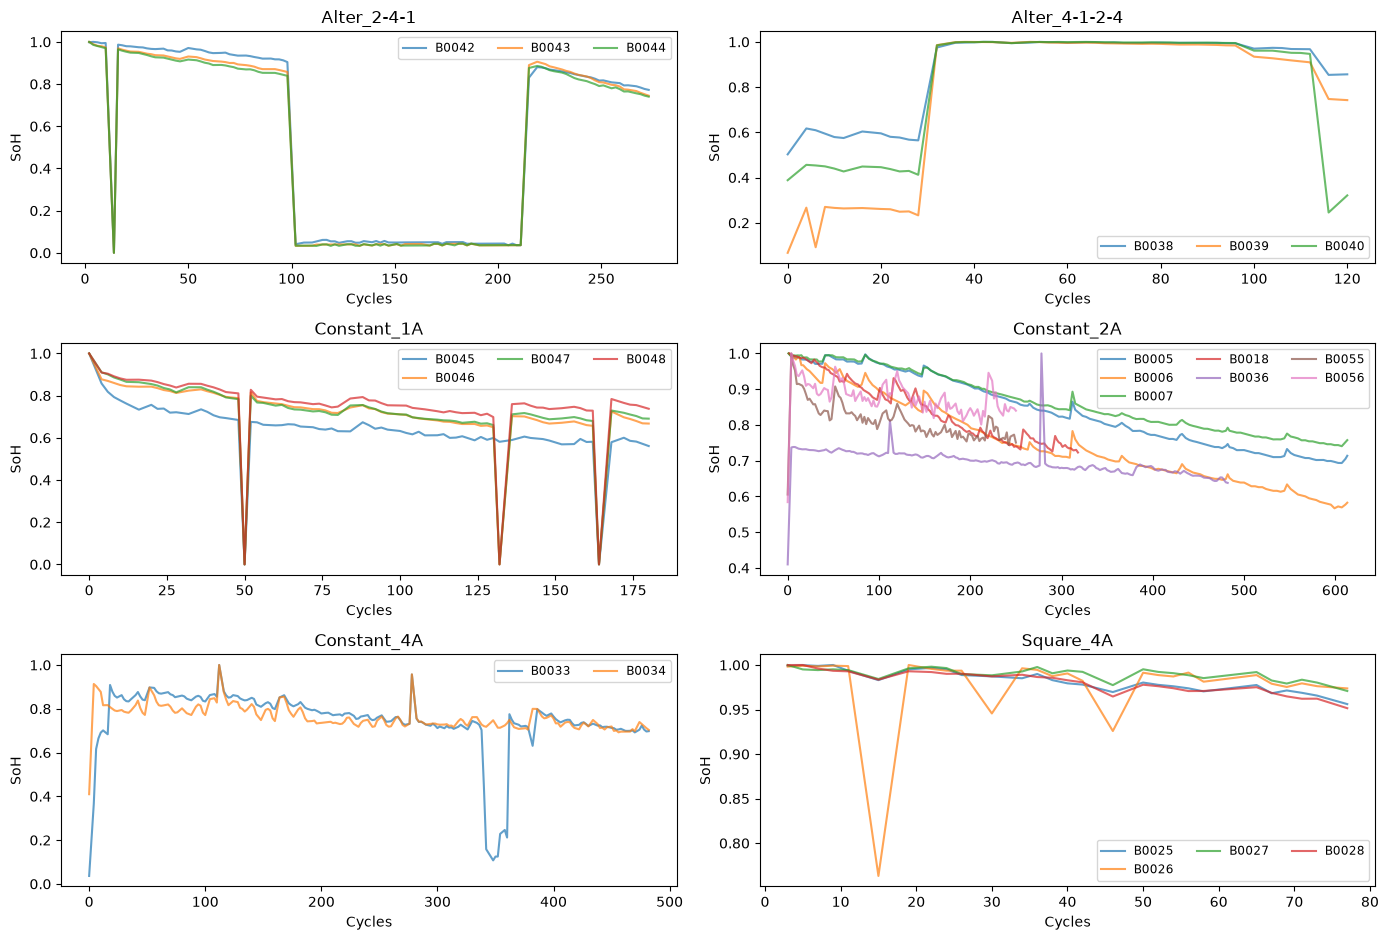

In [15]:
# Re-plot SoH vs. cycle number by discharge type on the cleaned dataset
alt_241 = discharge_df[discharge_df['Discharge_Type'] == 'Alter_2-4-1']
alt_4124 = discharge_df[discharge_df['Discharge_Type'] == 'Alter_4-1-2-4']
const_1A = discharge_df[discharge_df['Discharge_Type'] == 'Constant_1A']
const_2A = discharge_df[discharge_df['Discharge_Type'] == 'Constant_2A']
const_4A = discharge_df[discharge_df['Discharge_Type'] == 'Constant_4A']
square_4A = discharge_df[discharge_df['Discharge_Type'] == 'Square_4A']

discharge_types = {
    "Alter_2-4-1": alt_241,
    "Alter_4-1-2-4": alt_4124,
    "Constant_1A": const_1A,
    "Constant_2A": const_2A,
    "Constant_4A": const_4A,
    "Square_4A": square_4A,
}


fig, axes = plt.subplots(3, 2, figsize=(14, 10), sharex=False, sharey=False)
axes = axes.flatten()

for ax, (label, df) in zip(axes, discharge_types.items()):
    for cell_id, group in df.groupby("Cell_ID"):
        ax.plot(group["Cycle_Number"], group["SoH"], label=cell_id, alpha=0.7)
    ax.set_title(label)
    ax.set_xlabel("Cycles")
    ax.set_ylabel("SoH")
    ax.legend(fontsize="small", loc="best", ncol=3)

plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()


In [16]:
#Check the correlation matrix
numeric_cols = discharge_df.select_dtypes(include='number')
disc_corr_mat = numeric_cols.corr()
disc_corr_mat

,Voltage_measured,Current_measured,Temperature_measured,Current_load,Voltage_load,Time,Cycle_Number,Ambient_Temperature,Capacity,discharge_current_A,ambient_C,cutoff_V,endoflife_criteria,SoH
Voltage_measured,1.000000,0.400522,-0.090255,-0.387048,0.191238,-0.349796,-0.041045,0.154336,0.070457,0.001841,0.074249,0.104150,-0.015887,0.025644
Current_measured,0.400522,1.000000,-0.223803,-0.865028,-0.200369,0.439816,-0.129788,-0.126988,-0.118328,-0.062068,-0.209217,-0.045814,0.090056,-0.005080
Temperature_measured,-0.090255,-0.223803,1.000000,0.174075,-0.157159,0.062183,0.142910,0.908720,0.537887,0.660877,0.826298,-0.076941,-0.557537,0.296155
Current_load,-0.387048,-0.865028,0.174075,1.000000,0.143407,-0.381211,0.186527,0.083795,0.012889,0.088423,0.119998,0.025833,-0.131102,-0.070018
Voltage_load,0.191238,-0.200369,-0.157159,0.143407,1.000000,-0.236222,-0.076828,0.028559,0.250252,-0.511091,-0.180690,0.352037,0.238142,0.267276
Time,-0.349796,0.439816,0.062183,-0.381211,-0.236222,1.000000,-0.213378,0.070194,0.181575,0.063825,-0.068737,-0.043145,0.013966,0.267947
Cycle_Number,-0.041045,-0.129788,0.142910,0.186527,-0.076828,-0.213378,1.000000,0.067600,-0.132983,-0.028019,0.339757,0.028143,-0.024998,-0.338317
Ambient_Temperature,0.154336,-0.126988,0.908720,0.083795,0.028559,0.070194,0.067600,1.000000,0.613353,0.604095,0.903489,0.028358,-0.552749,0.376794
Capacity,0.070457,-0.118328,0.537887,0.012889,0.250252,0.181575,-0.132983,0.613353,1.000000,0.369729,0.572112,0.167344,-0.190220,0.827608
discharge_current_A,0.001841,-0.062068,0.660877,0.088423,-0.511091,0.063825,-0.028019,0.604095,0.369729,1.000000,0.604095,-0.384580,-0.502162,0.303490


Next steps would be to model using XGBoost, RandomForest, and LightGBM.

# 7. Additional EDA
Quick sanity checks on `discharge_df`.

In [17]:
# Quick sanity check on the cleaned discharge dataframe
discharge_df.info()

<class 'pandas.DataFrame'>
Index: 687175 entries, 0 to 746333
Data columns (total 18 columns):
 #   Column                Non-Null Count   Dtype         
---  ------                --------------   -----         
 0   Voltage_measured      687175 non-null  float64       
 1   Current_measured      687175 non-null  float64       
 2   Temperature_measured  687175 non-null  float64       
 3   Current_load          687175 non-null  float64       
 4   Voltage_load          687175 non-null  float64       
 5   Time                  687175 non-null  float64       
 6   Cell_ID               687175 non-null  str           
 7   Cycle_Number          687175 non-null  int64         
 8   Ambient_Temperature   687175 non-null  int64         
 9   Time_abs              687175 non-null  datetime64[us]
 10  Capacity              687175 non-null  float64       
 11  discharge_mode        687175 non-null  str           
 12  discharge_current_A   535668 non-null  float64       
 13  ambient_C      

In [18]:
#grouping the discharge dataframe based on cycling patterns and creating a dictionary of the discharge types
alt_241 = discharge_df[discharge_df['Discharge_Type'] == 'Alter_2-4-1']
alt_4124 = discharge_df[discharge_df['Discharge_Type'] == 'Alter_4-1-2-4']
const_1A = discharge_df[discharge_df['Discharge_Type'] == 'Constant_1A']
const_2A = discharge_df[discharge_df['Discharge_Type'] == 'Constant_2A']
const_4A = discharge_df[discharge_df['Discharge_Type'] == 'Constant_4A']
square_4A = discharge_df[discharge_df['Discharge_Type'] == 'Square_4A']
discharge_types = {
    "Alter_2-4-1": alt_241,
    "Alter_4-1-2-4": alt_4124,
    "Constant_1A": const_1A,
    "Constant_2A": const_2A,
    "Constant_4A": const_4A,
    "Square_4A": square_4A,
}

# 8. Aggregate to Per-Cycle Summary Tables
Collapse the raw time-series rows into one row per (Cell_ID, Cycle_Number): `discharge_sum_df` summarizes each discharge cycle, `eis_sum_df` summarizes each impedance measurement cycle.

In [19]:
# Collapse discharge_df to one row per (Cell_ID, Cycle_Number) with per-cycle summary stats
discharge_sum_df = (
    discharge_df
    .groupby(["Cell_ID", "Cycle_Number"])
    .agg({
        "Time": lambda x: x.max() - x.min(),
        "Discharge_Type": "first",
        "discharge_current_A": "first",
        "Voltage_measured": lambda x: x.iloc[0] - x.iloc[-1],
        "Current_measured": "min",
        "Temperature_measured": lambda x: x.max() - x.iloc[0],
        "Ambient_Temperature": "mean",
        "Voltage_load": "mean",
        "Current_load": "mean",
        "cutoff_V": "mean",
        "Capacity": "mean",
        "SoH": "mean",
    })
    .reset_index()
)
discharge_sum_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2375 entries, 0 to 2374
Data columns (total 14 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Cell_ID               2375 non-null   str    
 1   Cycle_Number          2375 non-null   int64  
 2   Time                  2375 non-null   float64
 3   Discharge_Type        2375 non-null   str    
 4   discharge_current_A   1831 non-null   float64
 5   Voltage_measured      2375 non-null   float64
 6   Current_measured      2375 non-null   float64
 7   Temperature_measured  2375 non-null   float64
 8   Ambient_Temperature   2375 non-null   float64
 9   Voltage_load          2375 non-null   float64
 10  Current_load          2375 non-null   float64
 11  cutoff_V              2375 non-null   float64
 12  Capacity              2375 non-null   float64
 13  SoH                   2375 non-null   float64
dtypes: float64(11), int64(1), str(2)
memory usage: 285.3 KB


In [20]:
# Collapse eis_df to one row per (Cell_ID, Cycle_Number), tagged as 'EIS' for merging
eis_sum_df = (
    eis_df
    .groupby(["Cell_ID", "Cycle_Number"])
    .agg({
        "Ambient_Temperature":"mean",
        "R_Electrolyte": "mean",
        "R_Charge_Transfer": "mean"
    })
    .reset_index()
)
eis_sum_df["Discharge_Type"] = "EIS" #to ease merging with the discharge database

eis_sum_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1766 entries, 0 to 1765
Data columns (total 6 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Cell_ID              1766 non-null   str    
 1   Cycle_Number         1766 non-null   int64  
 2   Ambient_Temperature  1766 non-null   float64
 3   R_Electrolyte        1766 non-null   float64
 4   R_Charge_Transfer    1766 non-null   float64
 5   Discharge_Type       1766 non-null   str    
dtypes: float64(3), int64(1), str(2)
memory usage: 88.3 KB


# 9. Merge EIS Features into Charge-Discharge Summary
EIS cycles don't align 1:1 with discharge cycles, so shift EIS cycle numbers +/-1 to match the discharge cycle immediately before/after each impedance scan, merge both into `discharge_eis_df`, and drop rows with missing EIS data to get `discharge_eis_clean`.

In [21]:
eis_dis = eis_sum_df.copy()
eis_dis['Cycle_Number'] = eis_dis['Cycle_Number'] - 1

eis_charge = eis_sum_df.copy()
eis_charge['Cycle_Number'] = eis_charge['Cycle_Number'] + 1

# Merge discharge info
discharge_eis_df = discharge_sum_df.merge(
    eis_dis[['Cell_ID', 'Cycle_Number', 'R_Electrolyte', 'R_Charge_Transfer']],
    on=['Cell_ID', 'Cycle_Number'],
    how='left'
)
discharge_eis_df.rename(columns={
    'R_Electrolyte': 're_dis',
    'R_Charge_Transfer': 'rct_dis'
}, inplace=True)

# Merge charge info
discharge_eis_df = discharge_eis_df.merge(
    eis_charge[['Cell_ID', 'Cycle_Number', 'R_Electrolyte', 'R_Charge_Transfer']],
    on=['Cell_ID', 'Cycle_Number'],
    how='left'
)
discharge_eis_df.rename(columns={
    'R_Electrolyte': 're_charge',
    'R_Charge_Transfer': 'rct_charge'
}, inplace=True)

discharge_eis_df.head()

,Cell_ID,Cycle_Number,Time,Discharge_Type,discharge_current_A,Voltage_measured,Current_measured,Temperature_measured,Ambient_Temperature,Voltage_load,Current_load,cutoff_V,Capacity,SoH,re_dis,rct_dis,re_charge,rct_charge
0,B0005,1,3690.234,Constant_2A,2.0,0.914322,-2.018015,14.652147,24.0,2.404944,-1.805570,2.7,1.856487,1.000000,NaN,NaN,NaN,NaN
1,B0005,3,3672.344,Constant_2A,2.0,0.889528,-2.016821,14.335646,24.0,2.399260,-1.804583,2.7,1.846327,0.994527,NaN,NaN,NaN,NaN
2,B0005,5,3651.641,Constant_2A,2.0,0.860736,-2.016574,14.084531,24.0,2.397969,-1.803575,2.7,1.835349,0.988614,NaN,NaN,NaN,NaN
3,B0005,7,3631.563,Constant_2A,2.0,0.874279,-2.015936,14.108068,24.0,2.408289,-1.812863,2.7,1.835263,0.988567,NaN,NaN,NaN,NaN
4,B0005,9,3629.172,Constant_2A,2.0,0.882802,-2.017426,14.140596,24.0,2.408505,-1.812876,2.7,1.834646,0.988235,NaN,NaN,NaN,NaN


[re_dis], [rct_dis], [re_charge], and [rct_charge] shows NaN because the impedance measurements happen at different cycles than discharge cycles, not to mention for B0005 the first impedance measurement happened at Cycle 40.

In [22]:
# Create columns in discharge_sum_df
dis_sum_df = discharge_sum_df.copy()

In [23]:
# Check null/non-null counts per column after merging EIS into the discharge summary
info_df = pd.DataFrame({
    'dtype': discharge_eis_df.dtypes,
    'num_nulls': discharge_eis_df.isnull().sum(),
    'num_non_null': discharge_eis_df.notnull().sum()
})
info_df


,dtype,num_nulls,num_non_null
Cell_ID,str,0,2375
Cycle_Number,int64,0,2375
Time,float64,0,2375
Discharge_Type,str,0,2375
discharge_current_A,float64,544,1831
Voltage_measured,float64,0,2375
Current_measured,float64,0,2375
Temperature_measured,float64,0,2375
Ambient_Temperature,float64,0,2375
Voltage_load,float64,0,2375


In [24]:
# Drop rows with missing EIS data and move Capacity/SoH to the end of the column order
discharge_eis_clean = discharge_eis_df.dropna()
discharge_eis_clean = discharge_eis_clean[[c for c in discharge_eis_df.columns if c not in ['Capacity','SoH']] + ['Capacity','SoH']]

discharge_eis_clean.info()

<class 'pandas.DataFrame'>
Index: 479 entries, 19 to 2362
Data columns (total 18 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Cell_ID               479 non-null    str    
 1   Cycle_Number          479 non-null    int64  
 2   Time                  479 non-null    float64
 3   Discharge_Type        479 non-null    str    
 4   discharge_current_A   479 non-null    float64
 5   Voltage_measured      479 non-null    float64
 6   Current_measured      479 non-null    float64
 7   Temperature_measured  479 non-null    float64
 8   Ambient_Temperature   479 non-null    float64
 9   Voltage_load          479 non-null    float64
 10  Current_load          479 non-null    float64
 11  cutoff_V              479 non-null    float64
 12  re_dis                479 non-null    float64
 13  rct_dis               479 non-null    float64
 14  re_charge             479 non-null    float64
 15  rct_charge            479 non-null   

# 10. Saving post-EDA dataframes

In [25]:
charge_df.to_pickle("charge_df_EDA.pkl")
discharge_df.to_pickle("discharge_df_EDA.pkl")
eis_df.to_pickle("eis_df_EDA.pkl")
discharge_eis_clean.to_pickle("discharge_eis_clean.pkl")

The machine learning and training will be covered in the next notebook file.